# 📊 Sales Data Analysis

## تحليل بيانات مبيعات محل باستخدام Python

### Project Objective

The goal of this project is to analyze sales data and identify the main sales trends, including:

* Cleaning and preparing the data
* Calculating total sales
* Identifying the best-selling product
* Finding the day with the highest sales
* Visualizing sales by product
* Visualizing sales by day
* Summarizing the main findings in a simple report


In [14]:
import pandas as pd
import matplotlib.pyplot as plt

In [15]:
from google.colab import files

uploaded = files.upload()

Saving GDqsMA7CEcuaiJqmLENXEzFbclIpMpFj.xlsx to GDqsMA7CEcuaiJqmLENXEzFbclIpMpFj (2).xlsx


In [19]:
df = pd.read_excel("GDqsMA7CEcuaiJqmLENXEzFbclIpMpFj.xlsx")

df.head()

,Date,Product,Quantity,Unit Price (EGP),Total Sales (EGP)
0,2026-08-01,Notebook,3,45,135
1,2026-08-01,Pen,10,10,100
2,2026-08-02,Notebook,5,45,225
3,2026-08-02,Water Bottle,2,120,240
4,2026-08-03,Pen,15,10,150


## 1. Data Overview

First, we inspect the dataset to understand its structure, columns, and data types.


In [20]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

df.info()

Number of rows: 18
Number of columns: 5
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18 entries, 0 to 17
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Date               18 non-null     object
 1   Product            18 non-null     object
 2   Quantity           18 non-null     int64 
 3   Unit Price (EGP)   18 non-null     int64 
 4   Total Sales (EGP)  18 non-null     int64 
dtypes: int64(3), object(2)
memory usage: 852.0+ bytes


In [21]:
df.describe(include="all")

,Date,Product,Quantity,Unit Price (EGP),Total Sales (EGP)
count,18,18,18.000000,18.000000,18.000000
unique,9,4,NaN,NaN,NaN
top,2026-08-01,Notebook,NaN,NaN,NaN
freq,2,5,NaN,NaN,NaN
mean,NaN,NaN,6.666667,119.722222,314.166667
std,NaN,NaN,5.901146,132.891732,190.766642
min,NaN,NaN,1.000000,10.000000,100.000000
25%,NaN,NaN,2.250000,18.750000,180.000000
50%,NaN,NaN,4.500000,45.000000,255.000000
75%,NaN,NaN,9.250000,120.000000,357.500000


## 2. Data Cleaning

In this step, we check for missing values and duplicate records and make sure that the date and sales columns are correctly formatted.


In [22]:
# Check missing values
print("Missing values:")
print(df.isnull().sum())

Missing values:
Date                 0
Product              0
Quantity             0
Unit Price (EGP)     0
Total Sales (EGP)    0
dtype: int64


In [23]:
# Check duplicate rows
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [28]:
# تحويل التاريخ

df["Date"] = pd.to_datetime(df["Date"])


In [16]:
# التأكد من صحة إجمالي المبيعات

df["Total Sales (EGP)"] = df["Quantity"] * df["Unit Price (EGP)"]

## 3. Total Sales

We calculate the total revenue generated during the analyzed period.


In [29]:
total_sales = df["Total Sales (EGP)"].sum()

print(f"Total Sales: {total_sales:,.2f} EGP")

Total Sales: 5,655.00 EGP


## 4. Best-Selling Product

We calculate the total quantity sold for each product to identify the best-selling product by units.


In [30]:
product_quantity = df.groupby("Product")["Quantity"].sum()

print(product_quantity)

Product
Backpack         6
Notebook        25
Pen             75
Water Bottle    14
Name: Quantity, dtype: int64


In [31]:
best_selling_product = product_quantity.idxmax()
best_selling_quantity = product_quantity.max()

print(f"Best-Selling Product: {best_selling_product}")
print(f"Quantity Sold: {best_selling_quantity}")

Best-Selling Product: Pen
Quantity Sold: 75


## 5. Sales Value by Product

We also compare products based on their total sales value.


In [32]:
product_sales = df.groupby("Product")["Total Sales (EGP)"].sum()

print(product_sales)

Product
Backpack        2100
Notebook        1125
Pen              750
Water Bottle    1680
Name: Total Sales (EGP), dtype: int64


In [33]:
highest_sales_product = product_sales.idxmax()
highest_sales_value = product_sales.max()

print(f"Product with Highest Sales Value: {highest_sales_product}")
print(f"Sales Value: {highest_sales_value:,.2f} EGP")

Product with Highest Sales Value: Backpack
Sales Value: 2,100.00 EGP


## 6. Highest Sales Day

We calculate the total sales for each day and identify the day with the highest sales.


In [34]:
daily_sales = df.groupby("Date")["Total Sales (EGP)"].sum()

print(daily_sales)

Date
2026-08-01     235
2026-08-02     465
2026-08-03     500
2026-08-04     300
2026-08-05    1060
2026-08-06     470
2026-08-07     830
2026-08-08     495
2026-08-09    1300
Name: Total Sales (EGP), dtype: int64


In [35]:
highest_sales_day = daily_sales.idxmax()
highest_sales_day_value = daily_sales.max()

print(f"Highest Sales Day: {highest_sales_day.date()}")
print(f"Sales: {highest_sales_day_value:,.2f} EGP")

Highest Sales Day: 2026-08-09
Sales: 1,300.00 EGP


لرسم البياني للمبيعات حسب المنتج

## 7. Sales by Product

The following chart shows the total sales value generated by each product.


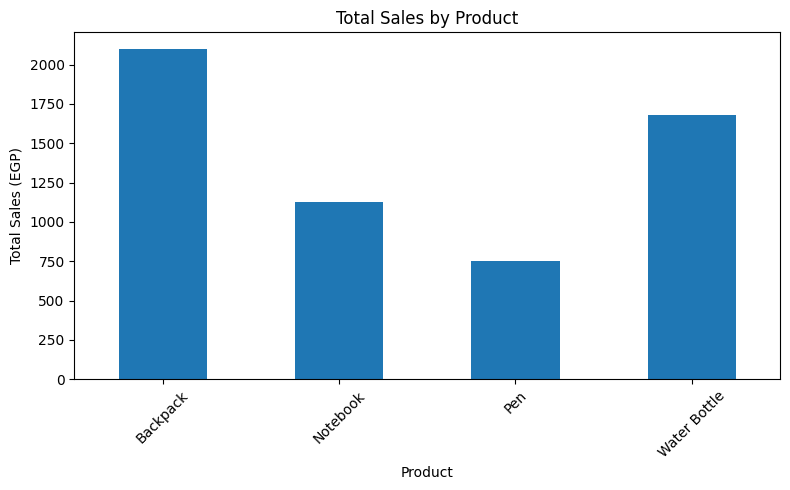

In [36]:
plt.figure(figsize=(8, 5))

product_sales.plot(kind="bar")

plt.title("Total Sales by Product")
plt.xlabel("Product")
plt.ylabel("Total Sales (EGP)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

 الرسم البياني للمبيعات حسب اليوم

## 8. Sales by Day

The following chart shows the total sales for each day during the analyzed period.



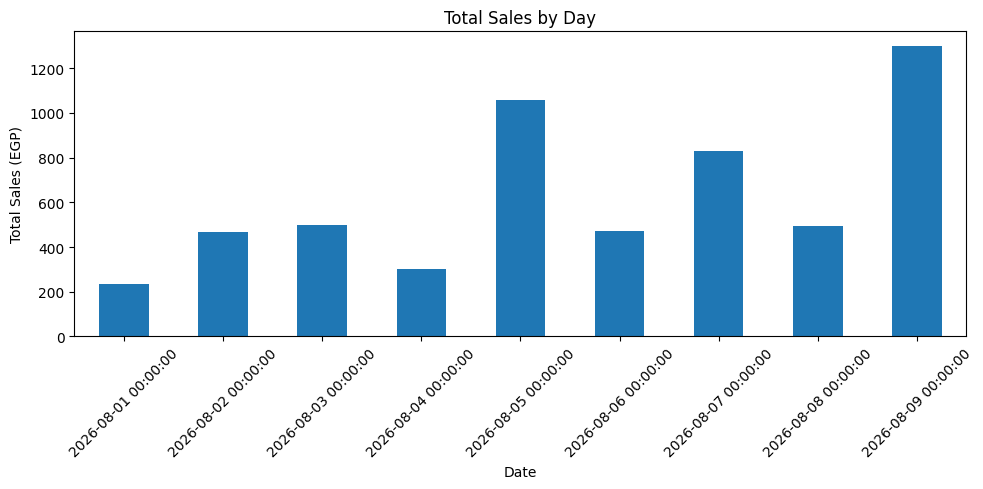

In [37]:
plt.figure(figsize=(10, 5))

daily_sales.plot(kind="bar")

plt.title("Total Sales by Day")
plt.xlabel("Date")
plt.ylabel("Total Sales (EGP)")
plt.xticks(rotation=45)
plt.tight_layout()

plt.show()

# 📋 Final Sales Analysis Report

## Key Findings

* **Total Sales:** 5,655 EGP
* **Best-Selling Product by Quantity:** Pen — 75 units
* **Product with the Highest Sales Value:** Backpack — 2,100 EGP
* **Highest Sales Day:** August 9, 2026 — 1,300 EGP

## Conclusion

The analysis shows that **Pen** was the best-selling product in terms of quantity, with 75 units sold.

However, **Backpack** generated the highest sales value, reaching 2,100 EGP.

The highest daily sales were recorded on **August 9, 2026**, with total sales of 1,300 EGP.

Overall, the dataset shows clear differences between product popularity by quantity and product performance by revenue.
